# Talabalar hayoti 
## Data Analysis — namunalar va mustaqil amaliy topshiriqlar
**Talaba:** ___Qosimov Saidobid___  |  **Guruh:** ___DI-1-24___

**Maqsad:** kichik o‘quv markazi datasetida usullarni o‘rganish, so‘ng ularni `Student_Depression_Dataset.csv` fayliga mustaqil qo‘llash.

### Ishlash tartibi
1. Asl CSV faylni ushbu notebook bilan bir papkaga joylashtiring (Google Colab’da Files bo‘limidan yuklang).
2. Tayyorlov katagini ishga tushiring. U 12 qatorli sun’iy dataset yaratadi; internetdan ma’lumot yuklamaydi.
3. Har bir **NAMUNA** katagini o‘rganing va bajaring. Keyingi **MUSTAQIL TOPSHIRIQ**ni asl dataset bilan bajaring.
4. Namuna o‘zgaruvchilari `sample_` prefiksi bilan (yoki alohida nom bilan) saqlanadi. Asl dataset uchun `df_raw`, `df` va boshqa mustaqil nomlardan foydalaning. Namuna fayllari `namuna_fayllari/` ichida, talaba fayllari esa joriy papkada saqlanadi.
5. Grafiklar va natijalar ostida qisqa izoh yozing. Asl CSV faylni o‘zgartirmang.

**Eslatma:** `Depression` klinik tashxis emas.

## Tayyorlov — 12 qatorli namunaviy dataset
Bu ma’lumotlar to‘qima bo‘lib, o‘quv markazi kurs qatnashchilarini ifodalaydi. Ataylab bitta shahar nomiga ortiqcha bo‘sh joy, nol qiymatlar va bitta katta xarajat kiritilgan. Ular tekshirish uchun xizmat qiladi.

| Namuna ustuni | Mazmuni | Asl datasetdagi o‘xshash ustun |
|---|---|---|
| Learner_ID | Qatnashchi raqami | — |
| Age_years | Yosh | Age |
| Score | Kurs bali (0–100) | CGPA |
| Month | Kurs oyi | Current_semester |
| Fee | Kurs xarajati (shartli birlik) | Cost_without_study |
| Learning_mode | Online / Onsite | Living_style |
| Team | Jamoasi bor: Yes / No | friend_circle |
| City | Shahar | Home_division |
| Completed | Kursni yakunlagan: Yes / No | Depression (faqat Yes/No formatining o‘xshashligi) |

Namuna va haqiqiy dataset ustunlari ma’nosi to‘liq bir xil emas; o‘xshash hisoblash usuli qo‘llanadi.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sample_dir = Path('namuna_fayllari')
sample_dir.mkdir(exist_ok=True)
sample_data = {
    'Learner_ID': list(range(1, 13)),
    'Age_years': [19, 20, 21, 22, 23, 24, 20, 22, 25, 21, 23, 24],
    'Score': [55, 68, 82, 90, 76, 88, 59, 80, 95, 72, 84, 65],
    'Month': [0, 1, 3, 4, 2, 5, 1, 3, 6, 2, 4, 3],
    'Fee': [0, 220, 300, 360, 280, 400, 240, 320, 1500, 260, 340, 310],
    'Learning_mode': ['Online', 'Onsite', 'Online', 'Onsite', 'Online', 'Onsite', 'Online', 'Onsite', 'Onsite', 'Online', 'Online', 'Onsite'],
    'Team': ['No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'No', 'Yes', 'No', 'Yes', 'No'],
    'City': ['Toshkent', 'Buxoro', 'Toshkent ', 'Samarqand', 'Buxoro', 'Toshkent', 'Samarqand', 'Buxoro', 'Toshkent', 'Samarqand', 'Buxoro', 'Toshkent'],
    'Completed': ['No', 'No', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'No', 'Yes', 'Yes']
}
sample_data_df = pd.DataFrame(sample_data)
sample_data_df.to_csv(sample_dir / 'training_sample.csv', index=False)
display(sample_data_df)

,Learner_ID,Age_years,Score,Month,Fee,Learning_mode,Team,City,Completed
0,1,19,55,0,0,Online,No,Toshkent,No
1,2,20,68,1,220,Onsite,Yes,Buxoro,No
2,3,21,82,3,300,Online,Yes,Toshkent,Yes
3,4,22,90,4,360,Onsite,Yes,Samarqand,Yes
4,5,23,76,2,280,Online,No,Buxoro,No
5,6,24,88,5,400,Onsite,Yes,Toshkent,Yes
6,7,20,59,1,240,Online,No,Samarqand,No
7,8,22,80,3,320,Onsite,No,Buxoro,Yes
8,9,25,95,6,1500,Onsite,Yes,Toshkent,Yes
9,10,21,72,2,260,Online,No,Samarqand,No


### Asl dataset ustunlari (topshiriqlar uchun ma’lumotnoma)
| Ustun | Mazmuni |
|---|---|
| Gender, Age | Jins va yosh |
| Family_background | Oilaning ijtimoiy-iqtisodiy toifasi |
| Relationship_status, Marital_status | Munosabat va nikoh holati |
| Living_style, friend_circle | Yashash tarzi va do‘stlar doirasi |
| Current_semester, CGPA | Semestr va umumiy o‘zlashtirish ko‘rsatkichi |
| Health_condition, Depression | Salomatlik toifasi va Yes/No belgisi |
| Cost_without_study | O‘qishdan tashqari xarajatlar |
| Home_division | Uy hududi |

---
# 1. Ma’lumotlar tahliliga kirish

## 01. Tahlil maqsadi

### NAMUNA — kichik datasetda yechim

Har bir qator o‘quv markazidagi bitta kurs qatnashchisini ifodalaydi. Maqsad — qatnashchilarning kurs natijalari, xarajatlari va kursni yakunlash holatini guruhlar bo‘yicha tahlil qilish.

### MUSTAQIL TOPSHIRIQ 01 — Student_Depression_Dataset.csv

Datasetdagi bitta qator nimani ifodalashini tushuntiring. Tahlilning maqsadini 2–3 gapda yozing.

**Javobingiz:**

Datasetdagi har bir qator bitta talabaga tegishli ma’lumotlarni ifodalaydi. Tahlilning maqsadi talabalar yoshi, akademik ko‘rsatkichlari (CGPA), semestri, yashash tarzi, xarajatlari va Depression belgisi o‘rtasidagi statistik taqsimot hamda bog‘liqliklarni o‘rganishdir. Natijalar guruhlar kesimida umumlashtiriladi; ular sabab-oqibat yoki individual klinik tashxisni bildirmaydi.

## 02. Ustunlarni tasniflash

### NAMUNA — kichik datasetda yechim

**Sonli ustunlar:** `Learner_ID` (identifikator), `Age_years`, `Score`, `Month`, `Fee`. `Learner_ID` son shaklida bo‘lsa ham, statistik o‘lchov emas.

**Kategoriyali ustunlar:** `Learning_mode`, `Team`, `City`, `Completed`.

`Age_years` — qatnashchi yoshi, `Score` — 100 ballik natija, `Completed` — kursni yakunlagan yoki yakunlamaganini bildiruvchi Yes/No belgi.

### MUSTAQIL TOPSHIRIQ 02 — Student_Depression_Dataset.csv

Ustunlarni sonli va kategoriyali turlarga ajrating. CGPA, Age va Depression ustunlari nimani ifodalashini yozing.

**Javobingiz:**

**Sonli ustunlar:** Age, Current_semester, CGPA va Cost_without_study. Age — talabaning yoshi, Current_semester — o‘qiyotgan semestri, CGPA — umumiy akademik o‘zlashtirish ko‘rsatkichi, Cost_without_study — o‘qishdan tashqari xarajatlar.

**Kategoriyali ustunlar:** Gender, Family_background, Relationship_status, Marital_status, Living_style, friend_circle, Health_condition, Depression va Home_division. Depression ustuni Yes/No ko‘rinishidagi kategoriyali belgi hisoblanadi.

## 03. Tadqiqot savollari

### NAMUNA — kichik datasetda yechim

- Onlayn va auditoriya guruhlarining o‘rtacha xarajatlari qanday farq qiladi?
- Qatnashchilarning o‘rtacha kurs bali qancha?
- Jamoaga ega va ega bo‘lmagan qatnashchilarda kursni yakunlash ulushi qanday farq qiladi?

### MUSTAQIL TOPSHIRIQ 03 — Student_Depression_Dataset.csv

Uchta tadqiqot savolini yozing: xarajatlar, akademik natijalar va Depression belgisi bo‘yicha bittadan.

**Javobingiz:**

1. Talabalarning Living_style guruhlari bo‘yicha Cost_without_study xarajatlarining o‘rtacha qiymati qanday farq qiladi?
2. Current_semester va CGPA o‘rtasida qanday statistik bog‘liqlik mavjud?
3. Living_style va friend_circle guruhlarida Depression = Yes ulushi qanday farqlanadi?

---
# 2. Vektorlashgan hisob (NumPy)

## 04. CSV faylni yuklash va NumPy massivlari

### NAMUNA — kichik datasetda yechim

In [2]:
sample_raw = pd.read_csv(sample_dir / 'training_sample.csv')
ages = sample_raw['Age_years'].to_numpy()
scores = sample_raw['Score'].to_numpy()
fees = sample_raw['Fee'].to_numpy()
print('Yosh:', ages)
print('Ball:', scores)
print('Xarajat:', fees)

Yosh: [19 20 21 22 23 24 20 22 25 21 23 24]
Ball: [55 68 82 90 76 88 59 80 95 72 84 65]
Xarajat: [   0  220  300  360  280  400  240  320 1500  260  340  310]


### MUSTAQIL TOPSHIRIQ 04 — Student_Depression_Dataset.csv

CSV faylni Pandas read_csv yordamida vaqtincha yuklang. Age, CGPA va Cost_without_study ustunlarini alohida NumPy massivlariga aylantiring.

In [3]:
# CSV faylni notebook bilan bir papkaga joylashtiring.
csv_path = Path('Student_Depression_Dataset.csv')
if not csv_path.exists():
    candidates = list(Path('.').glob('**/Student_Depression_Dataset.csv'))
    if candidates:
        csv_path = candidates[0]
    else:
        raise FileNotFoundError(
            "Student_Depression_Dataset.csv topilmadi. CSV faylni notebook bilan bir papkaga yuklang."
        )

temp_df = pd.read_csv(csv_path)
ages = temp_df['Age'].to_numpy()
cgpa = temp_df['CGPA'].to_numpy()
costs = temp_df['Cost_without_study'].to_numpy()
print('Age:', ages[:10])
print('CGPA:', cgpa[:10])
print('Cost_without_study:', costs[:10])

Age: [22 19 23 20 21 24 21 19 21 22]
CGPA: [3.43 3.7  3.28 3.77 4.   3.8  3.5  2.71 3.1  3.34]
Cost_without_study: [10113 13815 15450 17413 16693 17244  1648 16782 13386 18131]


## 05. Minimum, maksimum va o‘rtacha

### NAMUNA — kichik datasetda yechim

In [4]:
print('Eng kichik yosh:', ages.min())
print('Eng katta yosh:', ages.max())
print('O‘rtacha yosh:', ages.mean())
print('O‘rtacha ball:', scores.mean())

Eng kichik yosh: 17
Eng katta yosh: 28
O‘rtacha yosh: 22.619175627240143
O‘rtacha ball: 76.16666666666667


**Namuna izohi:** O‘rtacha qiymat umumiy darajani, minimum va maksimum esa kuzatilgan chegaralarni ko‘rsatadi.

### MUSTAQIL TOPSHIRIQ 05 — Student_Depression_Dataset.csv

Yosh massivining minimum, maksimum va o‘rtacha qiymatini; CGPA massivining o‘rtacha qiymatini hisoblang.

In [5]:
print('Yosh minimumi:', np.nanmin(ages))
print('Yosh maksimumi:', np.nanmax(ages))
print('Yosh o‘rtachasi:', np.nanmean(ages))
print('CGPA o‘rtachasi:', np.nanmean(cgpa))

Yosh minimumi: 17
Yosh maksimumi: 28
Yosh o‘rtachasi: 22.619175627240143
CGPA o‘rtachasi: 3.4127531362007164


## 06. Boolean mask

### NAMUNA — kichik datasetda yechim

In [6]:
mask = scores >= 80
print('Shartga mos qiymatlar:', scores[mask])
print('80 va undan yuqori ball olganlar:', mask.sum())

Shartga mos qiymatlar: [82 90 88 80 95 84]
80 va undan yuqori ball olganlar: 6


**Namuna izohi:** Boolean mask har bir qiymat uchun True yoki False beradi. True qiymatlar yig‘indisi shartga mos qatorlar sonidir.

### MUSTAQIL TOPSHIRIQ 06 — Student_Depression_Dataset.csv

Boolean mask yordamida CGPA qiymati 3.5 va undan yuqori bo‘lgan talabalar sonini toping.

In [7]:
cgpa_mask = cgpa >= 3.5
print('CGPA >= 3.5 bo‘lgan talabalar soni:', int(cgpa_mask.sum()))

CGPA >= 3.5 bo‘lgan talabalar soni: 2203


## 07. Vektorlashgan 10% o‘sish

### NAMUNA — kichik datasetda yechim

In [8]:
new_fees = fees * 1.10
print('Asl qiymatlar:', fees[:5])
print('10% oshgan qiymatlar:', new_fees[:5])

Asl qiymatlar: [  0 220 300 360 280]
10% oshgan qiymatlar: [  0. 242. 330. 396. 308.]


**Namuna izohi:** Butun massiv bir martada 1.10 ga ko‘paytirildi. Asl massiv o‘zgarmaydi.

### MUSTAQIL TOPSHIRIQ 07 — Student_Depression_Dataset.csv

Xarajatlar 10% oshgan faraziy holat uchun yangi massiv yarating. Dastlabki 5 qiymatni asl massiv bilan solishtiring. Sikl ishlatmang.

In [9]:
costs_increased = costs * 1.10
comparison = pd.DataFrame({
    'Asl xarajat': costs[:5],
    '10% oshirilgan xarajat': costs_increased[:5]
})
display(comparison)

,Asl xarajat,10% oshirilgan xarajat
0,10113,11124.3
1,13815,15196.5
2,15450,16995.0
3,17413,19154.3
4,16693,18362.3


---
# 3. Pandas asoslari

## 08. DataFrame bilan tanishish

### NAMUNA — kichik datasetda yechim

In [10]:
print('Jadval hajmi:', sample_raw.shape)
print('Ustunlar:', sample_raw.columns.tolist())
display(sample_raw.head(5))
display(sample_raw.tail(5))
sample_raw.info()

Jadval hajmi: (12, 9)
Ustunlar: ['Learner_ID', 'Age_years', 'Score', 'Month', 'Fee', 'Learning_mode', 'Team', 'City', 'Completed']


,Learner_ID,Age_years,Score,Month,Fee,Learning_mode,Team,City,Completed
0,1,19,55,0,0,Online,No,Toshkent,No
1,2,20,68,1,220,Onsite,Yes,Buxoro,No
2,3,21,82,3,300,Online,Yes,Toshkent,Yes
3,4,22,90,4,360,Onsite,Yes,Samarqand,Yes
4,5,23,76,2,280,Online,No,Buxoro,No


,Learner_ID,Age_years,Score,Month,Fee,Learning_mode,Team,City,Completed
7,8,22,80,3,320,Onsite,No,Buxoro,Yes
8,9,25,95,6,1500,Onsite,Yes,Toshkent,Yes
9,10,21,72,2,260,Online,No,Samarqand,No
10,11,23,84,4,340,Online,Yes,Buxoro,Yes
11,12,24,65,3,310,Onsite,No,Toshkent,Yes


<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Learner_ID     12 non-null     int64
 1   Age_years      12 non-null     int64
 2   Score          12 non-null     int64
 3   Month          12 non-null     int64
 4   Fee            12 non-null     int64
 5   Learning_mode  12 non-null     str  
 6   Team           12 non-null     str  
 7   City           12 non-null     str  
 8   Completed      12 non-null     str  
dtypes: int64(5), str(4)
memory usage: 996.0 bytes


### MUSTAQIL TOPSHIRIQ 08 — Student_Depression_Dataset.csv

DataFrame hajmi, ustun nomlari, dastlabki va oxirgi 5 qatorini chiqaring. info() orqali turlarni tekshiring.

In [11]:
print('DataFrame hajmi:', temp_df.shape)
print('Ustun nomlari:', temp_df.columns.tolist())
display(temp_df.head())
display(temp_df.tail())
temp_df.info()

DataFrame hajmi: (4464, 13)
Ustun nomlari: ['Gender', 'Age', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'Current_semester', 'CGPA', 'friend_circle', 'Health_condition', 'Cost_without_study', 'Home_division', 'Depression']


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No
4463,Female,21,Lower Middle class,Single,Unmarried,Family,5,2.56,Yes,Abnormal,4000,Barisal,Yes


<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


## 09. Ustunlarni tanlash

### NAMUNA — kichik datasetda yechim

In [12]:
sample_selected = sample_raw[['Age_years', 'Score', 'Month', 'Completed']]
display(sample_selected)

,Age_years,Score,Month,Completed
0,19,55,0,No
1,20,68,1,No
2,21,82,3,Yes
3,22,90,4,Yes
4,23,76,2,No
5,24,88,5,Yes
6,20,59,1,No
7,22,80,3,Yes
8,25,95,6,Yes
9,21,72,2,No


### MUSTAQIL TOPSHIRIQ 09 — Student_Depression_Dataset.csv

Age, CGPA, Current_semester va Depression ustunlaridan alohida jadval yarating.

In [13]:
selected_df = temp_df[['Age', 'CGPA', 'Current_semester', 'Depression']].copy()
display(selected_df.head())

,Age,CGPA,Current_semester,Depression
0,22,3.43,8,Yes
1,19,3.70,2,Yes
2,23,3.28,8,Yes
3,20,3.77,2,No
4,21,4.00,1,Yes


## 10. Filtrlash va saralash

### NAMUNA — kichik datasetda yechim

In [14]:
sample_filtered = sample_raw[(sample_raw['Score'] >= 80) & (sample_raw['Month'] >= 3)]
display(sample_filtered.sort_values('Score', ascending=False).head(10))

,Learner_ID,Age_years,Score,Month,Fee,Learning_mode,Team,City,Completed
8,9,25,95,6,1500,Onsite,Yes,Toshkent,Yes
3,4,22,90,4,360,Onsite,Yes,Samarqand,Yes
5,6,24,88,5,400,Onsite,Yes,Toshkent,Yes
10,11,23,84,4,340,Online,Yes,Buxoro,Yes
2,3,21,82,3,300,Online,Yes,Toshkent,Yes
7,8,22,80,3,320,Onsite,No,Buxoro,Yes


**Namuna izohi:** Ikki shart `&` bilan bog‘lanadi. Har bir shart qavs ichida yoziladi.

### MUSTAQIL TOPSHIRIQ 10 — Student_Depression_Dataset.csv

CGPA ≥ 3.5 va Current_semester ≥ 5 bo‘lgan talabalarni filtrlang. Ularni CGPA bo‘yicha kamayish tartibida saralang va dastlabki 10 qatorni ko‘rsating.

In [15]:
filtered_df = temp_df[
    (temp_df['CGPA'] >= 3.5) &
    (temp_df['Current_semester'] >= 5)
].sort_values('CGPA', ascending=False)
display(filtered_df.head(10))

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
1396,Male,23,Lower Middle class,Single,Unmarried,Bachelor,5,4.0,No,Good,3000,Khulna,No
3291,Female,23,Middle class,In a Relationship,Unmarried,Bachelor,7,4.0,Yes,Good,2600,Chittagong,No
3282,Female,22,Rich class,Single,Married,Family,7,4.0,Yes,Normal,11000,Khulna,No
4228,Female,24,Middle class,Single,Married,Bachelor,5,4.0,Yes,Good,14512,Khulna,No
4275,Male,24,Middle class,Single,Married,Bachelor,5,4.0,Yes,Good,14512,Khulna,No
3373,Female,21,Middle class,In a Relationship,Unmarried,Family,5,4.0,Yes,Critical,13000,Barisal,Yes
3275,Female,22,Lower Middle class,In a Relationship,Unmarried,Bachelor,7,4.0,Yes,Critical,10000,Chittagong,Yes
1468,Male,23,Middle class,In a Relationship,Unmarried,Family,5,4.0,Yes,Abnormal,12000,Barisal,No
1257,Male,24,Middle class,Single,Unmarried,Bachelor,7,4.0,No,Good,12205,Khulna,No
1193,Male,25,Middle class,Single,Married,Family,5,4.0,No,Critical,15770,Khulna,Yes


## 11. Toifalar soni

### NAMUNA — kichik datasetda yechim

In [16]:
display(sample_raw['Learning_mode'].value_counts())
display(sample_raw['Team'].value_counts())

Learning_mode
Online    6
Onsite    6
Name: count, dtype: int64

Team
No     6
Yes    6
Name: count, dtype: int64

### MUSTAQIL TOPSHIRIQ 11 — Student_Depression_Dataset.csv

Living_style va friend_circle ustunlaridagi har bir toifaning sonini value_counts() orqali aniqlang.

In [17]:
display(temp_df['Living_style'].value_counts())
display(temp_df['friend_circle'].value_counts())

Living_style
Bachelor    2449
Family      2015
Name: count, dtype: int64

friend_circle
Yes    3215
No     1249
Name: count, dtype: int64

---
# 4. Ma’lumotlarni yuklash, saqlash va fayl formatlari

## 12. Asl va ishchi nusxa

### NAMUNA — kichik datasetda yechim

In [18]:
sample_raw = pd.read_csv(sample_dir / 'training_sample.csv')
sample_df = sample_raw.copy()
display(sample_df.head())

,Learner_ID,Age_years,Score,Month,Fee,Learning_mode,Team,City,Completed
0,1,19,55,0,0,Online,No,Toshkent,No
1,2,20,68,1,220,Onsite,Yes,Buxoro,No
2,3,21,82,3,300,Online,Yes,Toshkent,Yes
3,4,22,90,4,360,Onsite,Yes,Samarqand,Yes
4,5,23,76,2,280,Online,No,Buxoro,No


### MUSTAQIL TOPSHIRIQ 12 — Student_Depression_Dataset.csv

Asl CSV faylni df_raw nomi bilan qayta yuklang. Ishchi nusxani df nomi bilan yarating.

In [19]:
df_raw = pd.read_csv(csv_path)
df = df_raw.copy()
print('Asl jadval:', df_raw.shape)
print('Ishchi nusxa:', df.shape)

Asl jadval: (4464, 13)
Ishchi nusxa: (4464, 13)


## 13. CSV va JSON formatlarida saqlash

### NAMUNA — kichik datasetda yechim

In [20]:
sample_profile = sample_df[['Age_years', 'Score', 'Learning_mode', 'Fee', 'Completed']]
sample_profile.to_csv(sample_dir / 'training_profile.csv', index=False)
sample_profile.to_json(sample_dir / 'training_profile.json', orient='records', force_ascii=False)
print('Ikkala namunaviy fayl saqlandi.')

Ikkala namunaviy fayl saqlandi.


### MUSTAQIL TOPSHIRIQ 13 — Student_Depression_Dataset.csv

Age, CGPA, Living_style, Cost_without_study va Depression ustunlarini student_profile.csv hamda student_profile.json fayllariga saqlang (JSON uchun records formatidan foydalaning). CSV faylda indeksni saqlamang.

In [21]:
profile_columns = ['Age', 'CGPA', 'Living_style', 'Cost_without_study', 'Depression']
student_profile = df[profile_columns].copy()
student_profile.to_csv('student_profile.csv', index=False)
student_profile.to_json('student_profile.json', orient='records', force_ascii=False, indent=2)
display(student_profile.head())
print('CSV va JSON fayllari saqlandi.')

,Age,CGPA,Living_style,Cost_without_study,Depression
0,22,3.43,Bachelor,10113,Yes
1,19,3.70,Bachelor,13815,Yes
2,23,3.28,Family,15450,Yes
3,20,3.77,Family,17413,No
4,21,4.00,Family,16693,Yes


CSV va JSON fayllari saqlandi.


## 14. Fayllarni qayta yuklash

### NAMUNA — kichik datasetda yechim

In [22]:
sample_csv = pd.read_csv(sample_dir / 'training_profile.csv')
sample_json = pd.read_json(sample_dir / 'training_profile.json', orient='records')
print('Qatorlar soni mos:', len(sample_csv) == len(sample_json))
print('Ustunlar mos:', sample_csv.columns.tolist() == sample_json.columns.tolist())

Qatorlar soni mos: True
Ustunlar mos: True


### MUSTAQIL TOPSHIRIQ 14 — Student_Depression_Dataset.csv

Ikkala faylni qayta yuklang. Qatorlar soni va ustun nomlari mosligini tekshiring.

In [23]:
profile_csv = pd.read_csv('student_profile.csv')
profile_json = pd.read_json('student_profile.json', orient='records')
print('CSV qatorlar soni:', len(profile_csv))
print('JSON qatorlar soni:', len(profile_json))
print('Qatorlar soni mos:', len(profile_csv) == len(profile_json))
print('Ustun nomlari mos:', profile_csv.columns.tolist() == profile_json.columns.tolist())
print('CSV ustunlari:', profile_csv.columns.tolist())
print('JSON ustunlari:', profile_json.columns.tolist())

CSV qatorlar soni: 4464
JSON qatorlar soni: 4464
Qatorlar soni mos: True
Ustun nomlari mos: True
CSV ustunlari: ['Age', 'CGPA', 'Living_style', 'Cost_without_study', 'Depression']
JSON ustunlari: ['Age', 'CGPA', 'Living_style', 'Cost_without_study', 'Depression']


---
# 5. Ma’lumotlarni tozalash va tayyorlash

## 15. Bo‘sh va takrorlangan qiymatlar

### NAMUNA — kichik datasetda yechim

In [24]:
print('Bo‘sh qiymatlar:')
display(sample_df.isna().sum())
print('Takrorlangan qatorlar:', sample_df.duplicated().sum())

Bo‘sh qiymatlar:


Learner_ID       0
Age_years        0
Score            0
Month            0
Fee              0
Learning_mode    0
Team             0
City             0
Completed        0
dtype: int64

Takrorlangan qatorlar: 0


**Namuna izohi:** Namunada bo‘sh yoki to‘liq takrorlangan qator bo‘lmasligi mumkin. Bu ham tekshiruv natijasi.

### MUSTAQIL TOPSHIRIQ 15 — Student_Depression_Dataset.csv

Har bir ustundagi bo‘sh qiymatlar va to‘liq takrorlangan qatorlar sonini aniqlang. Agar mavjud bo‘lmasa, sun’iy ravishda xato yaratish shart emas.

In [25]:
print('Har bir ustundagi bo‘sh qiymatlar:')
display(df.isna().sum())
print('To‘liq takrorlangan qatorlar soni:', int(df.duplicated().sum()))

Har bir ustundagi bo‘sh qiymatlar:


Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

To‘liq takrorlangan qatorlar soni: 0


## 16. Matnlarni tozalash va turlar

### NAMUNA — kichik datasetda yechim

In [26]:
text_cols = sample_df.select_dtypes(include=['object', 'string']).columns
for col in text_cols:
    print(col, '— ortiqcha bo‘sh joyli qatorlar:', (sample_df[col] != sample_df[col].str.strip()).sum())
    sample_df[col] = sample_df[col].str.strip()
display(sample_df[['Age_years', 'Score', 'Fee']].dtypes)

Learning_mode — ortiqcha bo‘sh joyli qatorlar: 0
Team — ortiqcha bo‘sh joyli qatorlar: 0
City — ortiqcha bo‘sh joyli qatorlar: 1
Completed — ortiqcha bo‘sh joyli qatorlar: 0


Age_years    int64
Score        int64
Fee          int64
dtype: object

### MUSTAQIL TOPSHIRIQ 16 — Student_Depression_Dataset.csv

Matnli ustunlarda ortiqcha bo‘sh joylarni tekshiring va str.strip() bilan tozalang. Age, CGPA va xarajatlarning sonli turda ekanligini tekshiring.

In [27]:
text_columns = df.select_dtypes(include=['object', 'string']).columns
for col in text_columns:
    df[col] = df[col].str.strip()

for col in ['Age', 'CGPA', 'Cost_without_study']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print('Matnli ustunlar tozalandi.')
print('Sonli ustunlar turlari:')
display(df[['Age', 'CGPA', 'Cost_without_study']].dtypes)
print('Qolgan bo‘sh qiymatlar:')
display(df.isna().sum())

Matnli ustunlar tozalandi.
Sonli ustunlar turlari:


Age                     int64
CGPA                  float64
Cost_without_study      int64
dtype: object

Qolgan bo‘sh qiymatlar:


Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

## 17. Nol qiymatlarni tekshirish

### NAMUNA — kichik datasetda yechim

In [28]:
print('Month = 0:', (sample_df['Month'] == 0).sum())
print('Fee = 0:', (sample_df['Fee'] == 0).sum())
# Nol qiymat bepul kurs yoki boshlang‘ich bosqichni anglatishi mumkin.
# Sababi aniqlanmaguncha qatorlar o‘chirilmaydi.

Month = 0: 1
Fee = 0: 1


### MUSTAQIL TOPSHIRIQ 17 — Student_Depression_Dataset.csv

Current_semester yoki Cost_without_study qiymati 0 bo‘lgan qatorlar sonini alohida aniqlang. Ularning xato ekanligi tasdiqlanmaganligi sababli avtomatik o‘chirmang.

In [29]:
print('Current_semester = 0 bo‘lgan qatorlar:',
      int((df['Current_semester'] == 0).sum()))
print('Cost_without_study = 0 bo‘lgan qatorlar:',
      int((df['Cost_without_study'] == 0).sum()))
# Nol qiymatlar tasdiqlangan xato bo‘lmagani uchun o‘chirilmaydi.

Current_semester = 0 bo‘lgan qatorlar: 42
Cost_without_study = 0 bo‘lgan qatorlar: 2


## 18. Intervallarga ajratish

### NAMUNA — kichik datasetda yechim

In [30]:
sample_df['Age_band'] = pd.cut(sample_df['Age_years'], bins=[-np.inf, 20, 23, np.inf],
                               labels=['20 va kichik', '21–23', '24 va katta'])
sample_df['Score_band'] = pd.cut(sample_df['Score'], bins=[-np.inf, 60, 80, np.inf],
                                 labels=['60 dan kichik', '60–79', '80 va yuqori'], right=False)
display(sample_df[['Age_years', 'Age_band', 'Score', 'Score_band']])

,Age_years,Age_band,Score,Score_band
0,19,20 va kichik,55,60 dan kichik
1,20,20 va kichik,68,60–79
2,21,21–23,82,80 va yuqori
3,22,21–23,90,80 va yuqori
4,23,21–23,76,60–79
5,24,24 va katta,88,80 va yuqori
6,20,20 va kichik,59,60 dan kichik
7,22,21–23,80,80 va yuqori
8,25,24 va katta,95,80 va yuqori
9,21,21–23,72,60–79


**Namuna izohi:** `pd.cut()` qiymatlarni intervalga ajratadi. Asl topshiriqda CGPA chegaralari boshqacha: 3 va 3.5. 3.5 yuqori guruhga kirishi uchun intervalning chap tomoni yopiq bo‘lishi kerak (`right=False`).

### MUSTAQIL TOPSHIRIQ 18 — Student_Depression_Dataset.csv

Age_group ustunini yarating: 20 va undan kichik, 21–23, 24 va undan katta. CGPA_group ustunini yarating: 3 dan kichik, 3 dan 3.5 gacha (3.5 kirmaydi), 3.5 va undan yuqori.

In [31]:
df['Age_group'] = pd.cut(
    df['Age'],
    bins=[-np.inf, 20, 23, np.inf],
    labels=['20 va kichik', '21–23', '24 va katta']
)
df['CGPA_group'] = pd.cut(
    df['CGPA'],
    bins=[-np.inf, 3, 3.5, np.inf],
    labels=['3 dan kichik', '3 dan 3.5 gacha', '3.5 va yuqori'],
    right=False
)
display(df[['Age', 'Age_group', 'CGPA', 'CGPA_group']].head())

,Age,Age_group,CGPA,CGPA_group
0,22,21–23,3.43,3 dan 3.5 gacha
1,19,20 va kichik,3.70,3.5 va yuqori
2,23,21–23,3.28,3 dan 3.5 gacha
3,20,20 va kichik,3.77,3.5 va yuqori
4,21,21–23,4.00,3.5 va yuqori


## 19. Yes/No ni sonli belgiga aylantirish

### NAMUNA — kichik datasetda yechim

In [32]:
sample_df['Completed_flag'] = sample_df['Completed'].map({'Yes': 1, 'No': 0})
sample_df.to_csv(sample_dir / 'training_clean.csv', index=False)
display(sample_df[['Completed', 'Completed_flag']].head())

,Completed,Completed_flag
0,No,0
1,No,0
2,Yes,1
3,Yes,1
4,No,0


### MUSTAQIL TOPSHIRIQ 19 — Student_Depression_Dataset.csv

Depression ustunidan Yes uchun 1, No uchun 0 qiymatli Depression_flag ustunini yarating. Asl ustunni saqlang. Tayyor jadvalni students_clean.csv fayliga yozing.

In [33]:
df['Depression_flag'] = df['Depression'].map({'Yes': 1, 'No': 0})
print('Depression_flag qiymatlari:')
display(df['Depression_flag'].value_counts(dropna=False))
df.to_csv('students_clean.csv', index=False)
print('students_clean.csv saqlandi.')

Depression_flag qiymatlari:


Depression_flag
0    3263
1    1201
Name: count, dtype: int64

students_clean.csv saqlandi.


---
# 6. Birlashtirish, qo‘shish va qayta shakllantirish

## 20. concat()

### NAMUNA — kichik datasetda yechim

In [34]:
sample_df = pd.read_csv(sample_dir / 'training_clean.csv')
online = sample_df[sample_df['Learning_mode'] == 'Online']
onsite = sample_df[sample_df['Learning_mode'] == 'Onsite']
sample_combined = pd.concat([online, onsite], ignore_index=True)
print('Asl qatorlar:', len(sample_df))
print('Birlashtirilgan qatorlar:', len(sample_combined))

Asl qatorlar: 12
Birlashtirilgan qatorlar: 12


### MUSTAQIL TOPSHIRIQ 20 — Student_Depression_Dataset.csv

students_clean.csv faylini yuklang. Living_style bo‘yicha Bachelor va Family guruhlarini alohida DataFrame ga ajrating. concat() bilan qayta birlashtiring, qatorlar sonini tekshiring.

In [35]:
students_clean = pd.read_csv('students_clean.csv')
bachelor_df = students_clean[students_clean['Living_style'] == 'Bachelor']
family_df = students_clean[students_clean['Living_style'] == 'Family']
combined_df = pd.concat([bachelor_df, family_df], ignore_index=True)
print('Bachelor:', len(bachelor_df))
print('Family:', len(family_df))
print('Birlashtirilgan qatorlar:', len(combined_df))
print('Tanlangan guruhlar jami:', len(bachelor_df) + len(family_df))
display(combined_df.head())

Bachelor: 2449
Family: 2015
Birlashtirilgan qatorlar: 4464
Tanlangan guruhlar jami: 4464


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression,Age_group,CGPA_group,Depression_flag
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes,21–23,3 dan 3.5 gacha,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes,20 va kichik,3.5 va yuqori,1
2,Female,24,Middle class,Single,Unmarried,Bachelor,9,3.80,Yes,Normal,17244,Chittagong,No,24 va katta,3.5 va yuqori,0
3,Female,23,Middle class,Single,Unmarried,Bachelor,7,2.89,No,Normal,16211,Barisal,Yes,21–23,3 dan kichik,1
4,Male,25,Middle class,Single,Unmarried,Bachelor,8,3.26,Yes,Abnormal,17971,Khulna,Yes,24 va katta,3 dan 3.5 gacha,1


## 21. merge()

### NAMUNA — kichik datasetda yechim

In [36]:
city_count = sample_df.groupby('City').size().reset_index(name='Learner_count')
city_score = sample_df.groupby('City')['Score'].mean().reset_index(name='Mean_score')
sample_city_report = city_count.merge(city_score, on='City')
display(sample_city_report)

,City,Learner_count,Mean_score
0,Buxoro,4,77.000000
1,Samarqand,3,73.666667
2,Toshkent,5,77.000000


### MUSTAQIL TOPSHIRIQ 21 — Student_Depression_Dataset.csv

Home_division bo‘yicha talabalar soni va o‘rtacha CGPA hisoblangan ikkita alohida jadval yarating. merge() yordamida ularni hudud nomi bo‘yicha birlashtiring.

In [37]:
home_count = df.groupby('Home_division').size().reset_index(name='Student_count')
home_cgpa = df.groupby('Home_division')['CGPA'].mean().reset_index(name='Mean_CGPA')
home_summary = pd.merge(home_count, home_cgpa, on='Home_division')
display(home_summary.sort_values('Student_count', ascending=False))

,Home_division,Student_count,Mean_CGPA
2,Dhaka,1527,3.409430
3,Khulna,548,3.448796
5,Rajshahi,488,3.427787
7,Sylhet,445,3.354292
1,Chittagong,400,3.449750
6,Rangpur,363,3.373388
0,Barisal,355,3.403155
4,Mymensingh,338,3.433166


## 22. pivot_table()

### NAMUNA — kichik datasetda yechim

In [38]:
sample_pivot = pd.pivot_table(sample_df, index='Learning_mode', columns='Team',
                              values='Score', aggfunc='mean')
display(sample_pivot)

Team,No,Yes
Learning_mode,,
Online,65.5,83.00
Onsite,72.5,85.25


### MUSTAQIL TOPSHIRIQ 22 — Student_Depression_Dataset.csv

pivot_table() yordamida qatorlarda Living_style, ustunlarda friend_circle va qiymatlarda o‘rtacha CGPA bo‘lgan jadval yarating.

In [39]:
living_friend_pivot = pd.pivot_table(
    df,
    index='Living_style',
    columns='friend_circle',
    values='CGPA',
    aggfunc='mean'
)
display(living_friend_pivot)

friend_circle,No,Yes
Living_style,,
Bachelor,3.430539,3.453065
Family,3.343438,3.383157


## 23. crosstab() va foizlar

### NAMUNA — kichik datasetda yechim

In [40]:
sample_cross = pd.crosstab(sample_df['Age_band'], sample_df['Completed'])
display(sample_cross)
sample_yes_pct = sample_cross['Yes'] / sample_cross.sum(axis=1) * 100
display(sample_yes_pct.round(2))

Completed,No,Yes
Age_band,,
20 va kichik,3,0
21–23,2,4
24 va katta,0,3


Age_band
20 va kichik      0.00
21–23            66.67
24 va katta     100.00
dtype: float64

**Namuna izohi:** Har bir yosh guruhi uchun Yes soni o‘sha guruhning jami soniga bo‘linadi.

### MUSTAQIL TOPSHIRIQ 23 — Student_Depression_Dataset.csv

crosstab() yordamida Age_group va Depression kesishmasida talabalar soni jadvalini tuzing. Har bir yosh guruhida Yes ulushini foizda hisoblang.

In [41]:
age_depression_table = pd.crosstab(df['Age_group'], df['Depression'])
display(age_depression_table)
age_yes_percent = (
    age_depression_table['Yes'] / age_depression_table.sum(axis=1) * 100
)
print('Depression = Yes ulushi (%):')
display(age_yes_percent.rename('Yes_percent').to_frame())

Depression,No,Yes
Age_group,,
20 va kichik,449,229
21–23,1850,651
24 va katta,964,321


Depression = Yes ulushi (%):


,Yes_percent
Age_group,
20 va kichik,33.775811
21–23,26.029588
24 va katta,24.980545


---
# 7. Ma’lumotlarni statistik tahlil qilish

## 24. Tavsifiy statistika

### NAMUNA — kichik datasetda yechim

In [42]:
sample_stats = sample_df[['Age_years', 'Score', 'Fee']].describe()
display(sample_stats)
print('Fee o‘rtachasi:', sample_df['Fee'].mean())
print('Fee medianasi:', sample_df['Fee'].median())
print('Fee standart og‘ishi:', round(sample_df['Fee'].std(), 2))

,Age_years,Score,Fee
count,12.000000,12.000000,12.000000
mean,22.000000,76.166667,377.500000
std,1.858641,12.604713,367.500773
min,19.000000,55.000000,0.000000
25%,20.750000,67.250000,255.000000
50%,22.000000,78.000000,305.000000
75%,23.250000,85.000000,345.000000
max,25.000000,95.000000,1500.000000


Fee o‘rtachasi: 377.5
Fee medianasi: 305.0
Fee standart og‘ishi: 367.5


**Namuna izohi:** O‘rtacha barcha qiymatlarga bog‘liq; mediana tartiblangan qiymatlarning o‘rtasini bildiradi; standart og‘ish qiymatlarning o‘rtacha atrofidagi tarqalishini ko‘rsatadi. Namunadagi katta xarajat o‘rtachani yuqoriga siljitadi.

### MUSTAQIL TOPSHIRIQ 24 — Student_Depression_Dataset.csv

Age, CGPA va Cost_without_study uchun describe() natijasini chiqaring. O‘rtacha, mediana va standart og‘ish qiymatlarini izohlang.

In [43]:
age_cgpa_cost_stats = df[['Age', 'CGPA', 'Cost_without_study']].describe()
display(age_cgpa_cost_stats)
summary_values = df[['Age', 'CGPA', 'Cost_without_study']].agg(['mean', 'median', 'std']).T
summary_values.columns = ['O‘rtacha', 'Mediana', 'Standart og‘ish']
display(summary_values)

,Age,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000
mean,22.619176,3.412753,11242.978271
std,2.022980,0.385605,6640.144019
min,17.000000,2.250000,0.000000
25%,21.000000,3.150000,6100.000000
50%,23.000000,3.490000,9500.000000
75%,24.000000,3.700000,15439.000000
max,28.000000,4.000000,32000.000000


,O‘rtacha,Mediana,Standart og‘ish
Age,22.619176,23.00,2.022980
CGPA,3.412753,3.49,0.385605
Cost_without_study,11242.978271,9500.00,6640.144019


**Natija izohi:**

*Shu yerga qisqa izoh yozing.*

## 25. IQR

### NAMUNA — kichik datasetda yechim

In [44]:
q1 = sample_df['Fee'].quantile(0.25)
q3 = sample_df['Fee'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
sample_outliers = sample_df[(sample_df['Fee'] < lower) | (sample_df['Fee'] > upper)]
print('Q1:', q1, 'Q3:', q3, 'IQR:', iqr)
print('Chegaralar:', lower, upper)
print('Chegaradan tashqaridagi qiymatlar soni:', len(sample_outliers))
display(sample_outliers[['Learner_ID', 'Fee']])

Q1: 255.0 Q3: 345.0 IQR: 90.0
Chegaralar: 120.0 480.0
Chegaradan tashqaridagi qiymatlar soni: 2


,Learner_ID,Fee
0,1,0
8,9,1500


**Namuna izohi:** IQR asosida ajratilgan qiymatlar ehtimoliy chet qiymatlardir, ular xato ekanini isbotlamaydi.

### MUSTAQIL TOPSHIRIQ 25 — Student_Depression_Dataset.csv

Xarajatlarning Q1, Q3 va IQR qiymatlarini hisoblang. Q1 − 1.5 × IQR va Q3 + 1.5 × IQR chegaralaridan tashqaridagi qiymatlar sonini toping. Ularni avtomatik o‘chirmang.

In [45]:
q1 = df['Cost_without_study'].quantile(0.25)
q3 = df['Cost_without_study'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_mask = (df['Cost_without_study'] < lower_bound) | (df['Cost_without_study'] > upper_bound)
print('Q1:', q1, '| Q3:', q3, '| IQR:', iqr)
print('Quyi chegara:', lower_bound, '| Yuqori chegara:', upper_bound)
print('Chegaradan tashqaridagi qiymatlar soni:', int(outlier_mask.sum()))
# Ehtimoliy chet qiymatlar avtomatik o‘chirilmaydi.

Q1: 6100.0 | Q3: 15439.0 | IQR: 9339.0
Quyi chegara: -7908.5 | Yuqori chegara: 29447.5
Chegaradan tashqaridagi qiymatlar soni: 36


## 26. Guruhlangan statistika

### NAMUNA — kichik datasetda yechim

In [46]:
display(sample_df.groupby('Learning_mode')['Fee'].agg(['mean', 'median']))
display(sample_df['Score_band'].value_counts())

,mean,median
Learning_mode,,
Online,236.666667,270.0
Onsite,518.333333,340.0


Score_band
80 va yuqori     6
60–79            4
60 dan kichik    2
Name: count, dtype: int64

### MUSTAQIL TOPSHIRIQ 26 — Student_Depression_Dataset.csv

Living_style bo‘yicha o‘rtacha va median xarajatni; CGPA_group bo‘yicha talabalar sonini hisoblang.

In [47]:
living_cost_stats = df.groupby('Living_style')['Cost_without_study'].agg(['mean', 'median'])
cgpa_group_counts = df['CGPA_group'].value_counts(sort=False, dropna=False)
print('Living_style bo‘yicha xarajatlar:')
display(living_cost_stats)
print('CGPA_group bo‘yicha talabalar soni:')
display(cgpa_group_counts.rename('Student_count').to_frame())

Living_style bo‘yicha xarajatlar:


,mean,median
Living_style,,
Bachelor,11878.103307,10800.0
Family,10471.057072,8380.0


CGPA_group bo‘yicha talabalar soni:


,Student_count
CGPA_group,
3 dan kichik,587
3 dan 3.5 gacha,1674
3.5 va yuqori,2203


## 27. Ulush va guruh hajmi

### NAMUNA — kichik datasetda yechim

In [48]:
print('Umumiy yakunlash ulushi (%):', round(sample_df['Completed_flag'].mean() * 100, 2))
sample_mode_summary = sample_df.groupby('Learning_mode')['Completed_flag'].agg(['mean', 'count'])
sample_mode_summary['Percent'] = sample_mode_summary['mean'] * 100
sample_team_summary = sample_df.groupby('Team')['Completed_flag'].agg(['mean', 'count'])
sample_team_summary['Percent'] = sample_team_summary['mean'] * 100
display(sample_mode_summary[['count', 'Percent']].round(2))
display(sample_team_summary[['count', 'Percent']].round(2))

Umumiy yakunlash ulushi (%): 58.33


,count,Percent
Learning_mode,,
Online,6,33.33
Onsite,6,83.33


,count,Percent
Team,,
No,6,33.33
Yes,6,83.33


### MUSTAQIL TOPSHIRIQ 27 — Student_Depression_Dataset.csv

Depression_flag ning umumiy o‘rtachasini 100 ga ko‘paytirib Yes ulushini toping. Xuddi shu hisobni Living_style va friend_circle bo‘yicha alohida bajaring. Har bir guruhning sonini ham ko‘rsating.

In [49]:
overall_yes_percent = df['Depression_flag'].mean() * 100
print('Umumiy Depression = Yes ulushi (%):', round(overall_yes_percent, 2))
living_summary = df.groupby('Living_style')['Depression_flag'].agg(['mean', 'size'])
living_summary['Yes_percent'] = living_summary['mean'] * 100
living_summary = living_summary.rename(columns={'size': 'Student_count'})
display(living_summary[['Yes_percent', 'Student_count']])
friend_summary = df.groupby('friend_circle')['Depression_flag'].agg(['mean', 'size'])
friend_summary['Yes_percent'] = friend_summary['mean'] * 100
friend_summary = friend_summary.rename(columns={'size': 'Student_count'})
display(friend_summary[['Yes_percent', 'Student_count']])

Umumiy Depression = Yes ulushi (%): 26.9


,Yes_percent,Student_count
Living_style,,
Bachelor,28.338097,2449
Family,25.161290,2015


,Yes_percent,Student_count
friend_circle,,
No,34.267414,1249
Yes,24.043546,3215


## 28. Korrelyatsiya

### NAMUNA — kichik datasetda yechim

In [50]:
sample_corr = sample_df[['Age_years', 'Month', 'Score', 'Fee']].corr()
display(sample_corr.round(3))
# Faqat diagonal ustidagi qiymatlar: o‘z-o‘zi bilan korrelyatsiya va takroriy juftliklar olinmaydi.
upper_mask = np.triu(np.ones(sample_corr.shape, dtype=bool), k=1)
pairs = sample_corr.abs().where(upper_mask).stack()
col1, col2 = pairs.idxmax()
print('Eng kuchli juftlik:', col1, 'va', col2)
print('Korrelyatsiya:', round(sample_corr.loc[col1, col2], 3))

,Age_years,Month,Score,Fee
Age_years,1.000,0.867,0.691,0.673
Month,0.867,1.000,0.908,0.749
Score,0.691,0.908,1.000,0.649
Fee,0.673,0.749,0.649,1.000


Eng kuchli juftlik: Month va Score
Korrelyatsiya: 0.908


**Namuna izohi:** Korrelyatsiya ikki sonli o‘zgaruvchi orasidagi chiziqli bog‘liqlikni ko‘rsatadi. U sabab-oqibatni isbotlamaydi.

### MUSTAQIL TOPSHIRIQ 28 — Student_Depression_Dataset.csv

Age, Current_semester, CGPA va Cost_without_study orasidagi korrelyatsiya matritsasini hisoblang. Eng katta mutlaq korrelyatsiyaga ega ikki turli ustunni aniqlang. Korrelyatsiya sababiyatni anglatmasligini izohlang.

In [51]:
corr_columns = ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']
corr_matrix = df[corr_columns].corr()
display(corr_matrix.round(3))
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
strongest_pair = upper_triangle.abs().stack().idxmax()
strongest_value = corr_matrix.loc[strongest_pair[0], strongest_pair[1]]
print('Eng katta mutlaq korrelyatsiya juftligi:', strongest_pair)
print('Korrelyatsiya qiymati:', round(strongest_value, 3))
print('Korrelyatsiya bog‘liqlikni ko‘rsatadi, sabab-oqibatni isbotlamaydi.')

,Age,Current_semester,CGPA,Cost_without_study
Age,1.000,0.325,-0.065,-0.063
Current_semester,0.325,1.000,-0.008,0.014
CGPA,-0.065,-0.008,1.000,0.082
Cost_without_study,-0.063,0.014,0.082,1.000


Eng katta mutlaq korrelyatsiya juftligi: ('Age', 'Current_semester')
Korrelyatsiya qiymati: 0.325
Korrelyatsiya bog‘liqlikni ko‘rsatadi, sabab-oqibatni isbotlamaydi.


**Natija izohi:**

*Shu yerga qisqa izoh yozing.*

---
# 8. Ma’lumotlarni grafik tasvirlash 1

## 29. Histogram

### NAMUNA — kichik datasetda yechim

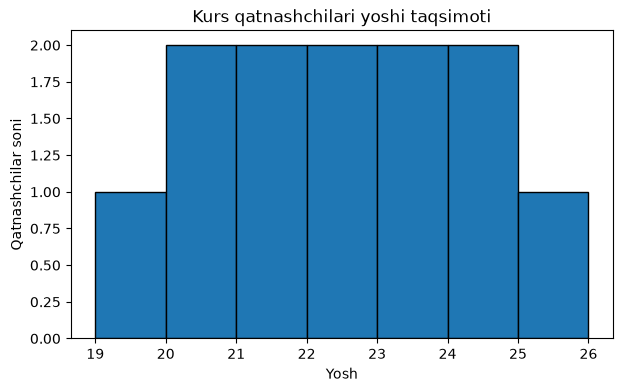

Eng ko‘p uchraydigan yosh(lar): [20, 21, 22, 23, 24]


In [52]:
plt.figure(figsize=(7, 4))
plt.hist(sample_df['Age_years'], bins=range(sample_df['Age_years'].min(), sample_df['Age_years'].max()+2), edgecolor='black')
plt.xlabel('Yosh')
plt.ylabel('Qatnashchilar soni')
plt.title('Kurs qatnashchilari yoshi taqsimoti')
plt.show()
print('Eng ko‘p uchraydigan yosh(lar):', sample_df['Age_years'].mode().tolist())

**Namuna izohi:** Histogram yoshlar taqsimotini ko‘rsatadi, mode esa eng ko‘p takrorlangan aniq yosh(lar)ni beradi.

### MUSTAQIL TOPSHIRIQ 29 — Student_Depression_Dataset.csv

Talabalar yoshining taqsimotini histogram orqali tasvirlang. Eng ko‘p uchraydigan yoshni aniqlang.

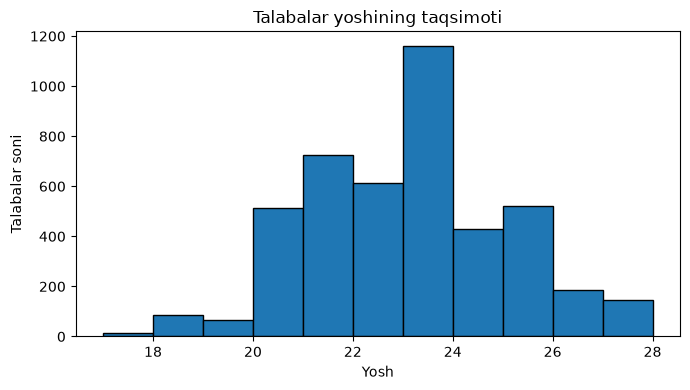

Eng ko‘p uchraydigan yosh(lar): [23]


In [53]:
plt.figure(figsize=(7, 4))
plt.hist(df['Age'].dropna(), bins='auto', edgecolor='black')
plt.xlabel('Yosh')
plt.ylabel('Talabalar soni')
plt.title('Talabalar yoshining taqsimoti')
plt.tight_layout()
plt.show()
age_modes = df['Age'].mode()
print('Eng ko‘p uchraydigan yosh(lar):', age_modes.tolist())

**Natija izohi:**

*Shu yerga qisqa izoh yozing.*

## 30. Gorizontal bar chart

### NAMUNA — kichik datasetda yechim

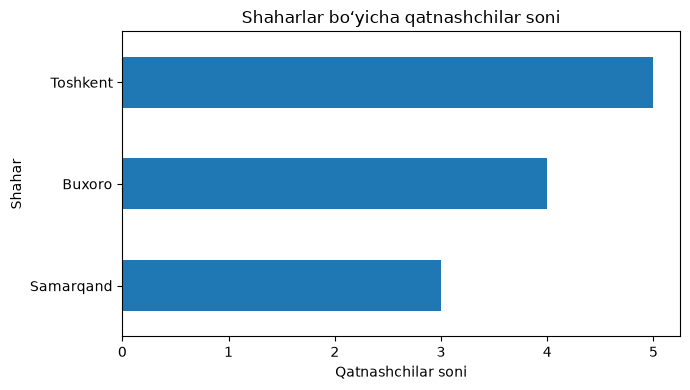

In [54]:
city_counts = sample_df['City'].value_counts().sort_values()
city_counts.plot(kind='barh', figsize=(7, 4))
plt.xlabel('Qatnashchilar soni')
plt.ylabel('Shahar')
plt.title('Shaharlar bo‘yicha qatnashchilar soni')
plt.tight_layout()
plt.show()

**Namuna izohi:** Uzunroq ustun ko‘proq qatnashchini anglatadi.

### MUSTAQIL TOPSHIRIQ 30 — Student_Depression_Dataset.csv

Home_division bo‘yicha talabalar sonini gorizontal bar chart orqali tasvirlang. Ustunlarni soni bo‘yicha saralang.

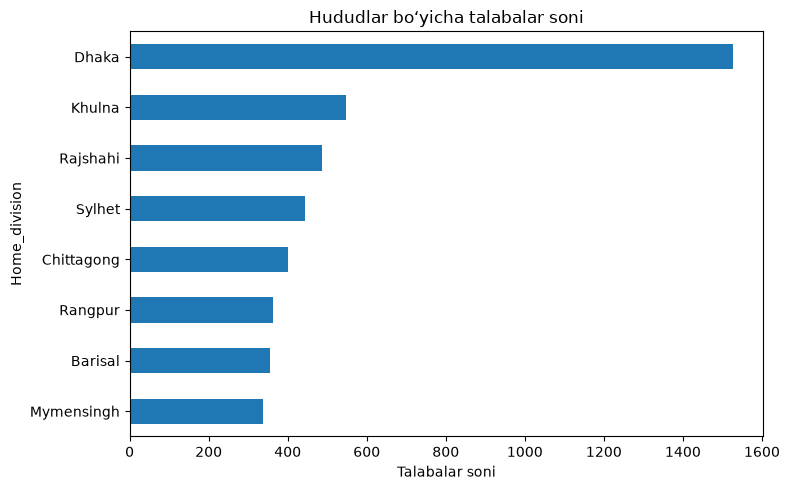

In [55]:
home_counts = df['Home_division'].value_counts().sort_values()
home_counts.plot(kind='barh', figsize=(8, 5))
plt.xlabel('Talabalar soni')
plt.ylabel('Home_division')
plt.title('Hududlar bo‘yicha talabalar soni')
plt.tight_layout()
plt.show()

**Natija izohi:**

*Shu yerga qisqa izoh yozing.*

## 31. Bar chart

### NAMUNA — kichik datasetda yechim

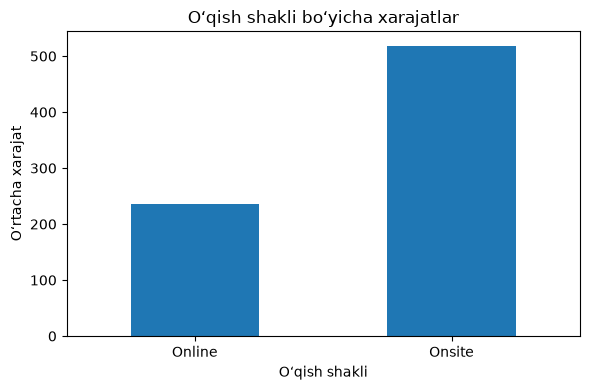

In [56]:
mode_fees = sample_df.groupby('Learning_mode')['Fee'].mean()
mode_fees.plot(kind='bar', figsize=(6, 4), rot=0)
plt.xlabel('O‘qish shakli')
plt.ylabel('O‘rtacha xarajat')
plt.title('O‘qish shakli bo‘yicha xarajatlar')
plt.tight_layout()
plt.show()

**Namuna izohi:** Ustun balandligi har bir guruhning o‘rtacha xarajatini bildiradi.

### MUSTAQIL TOPSHIRIQ 31 — Student_Depression_Dataset.csv

Living_style bo‘yicha o‘rtacha xarajatlarni bar chart yordamida taqqoslang. O‘qlarga nom va grafik sarlavhasini qo‘ying.

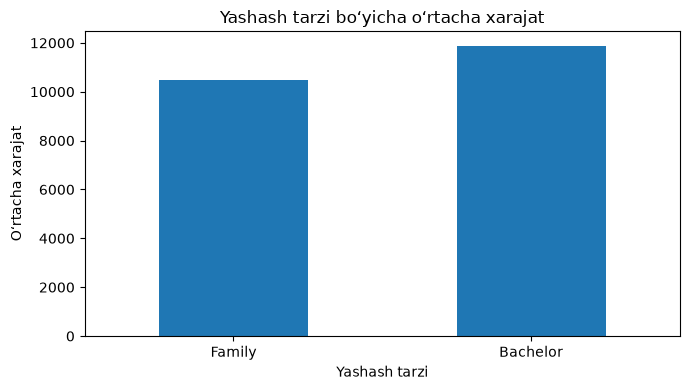

In [57]:
living_cost_mean = df.groupby('Living_style')['Cost_without_study'].mean().sort_values()
living_cost_mean.plot(kind='bar', figsize=(7, 4), rot=0)
plt.xlabel('Yashash tarzi')
plt.ylabel('O‘rtacha xarajat')
plt.title('Yashash tarzi bo‘yicha o‘rtacha xarajat')
plt.tight_layout()
plt.show()

**Natija izohi:**

*Shu yerga qisqa izoh yozing.*

## 32. Pie chart

### NAMUNA — kichik datasetda yechim

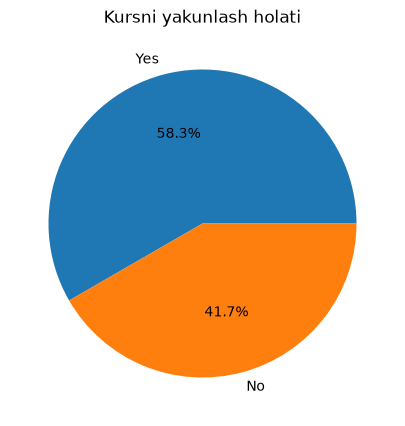

In [58]:
sample_df['Completed'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(5, 5), ylabel='')
plt.title('Kursni yakunlash holati')
plt.show()

**Namuna izohi:** Doiraning har bir bo‘lagi kursni yakunlash toifasining umumiy ulushini anglatadi.

### MUSTAQIL TOPSHIRIQ 32 — Student_Depression_Dataset.csv

Depression ustunidagi Yes va No toifalarining umumiy ulushini pie chart orqali foizlarda ko‘rsating.

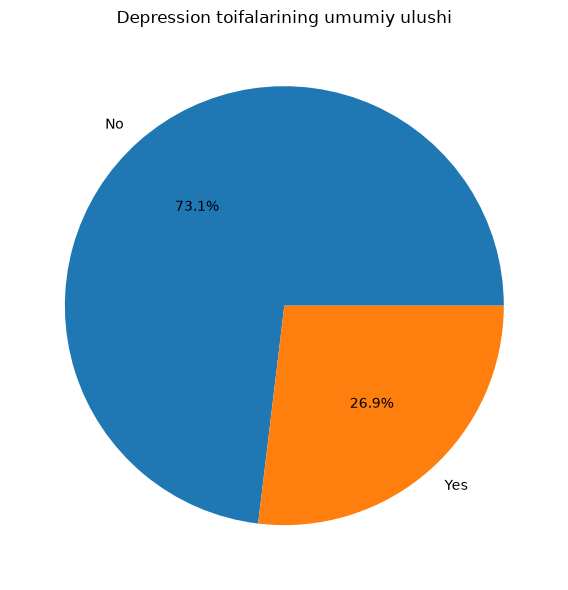

In [59]:
df['Depression'].value_counts().plot(
    kind='pie', autopct='%1.1f%%', figsize=(6, 6), ylabel=''
)
plt.title('Depression toifalarining umumiy ulushi')
plt.tight_layout()
plt.show()

**Natija izohi:**

*Shu yerga qisqa izoh yozing.*

---
# 9. Ma’lumotlarni grafik tasvirlash 2

## 33. Boxplot

### NAMUNA — kichik datasetda yechim

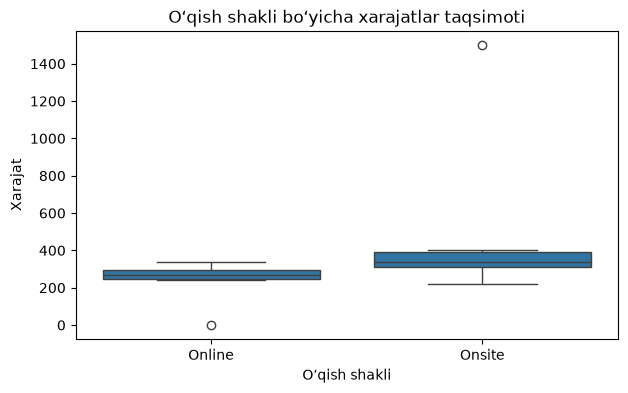

Learning_mode
Online    270.0
Onsite    340.0
Name: Fee, dtype: float64

In [60]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=sample_df, x='Learning_mode', y='Fee')
plt.xlabel('O‘qish shakli')
plt.ylabel('Xarajat')
plt.title('O‘qish shakli bo‘yicha xarajatlar taqsimoti')
plt.show()
display(sample_df.groupby('Learning_mode')['Fee'].median())

**Namuna izohi:** Quti ichidagi chiziq mediana, quti esa o‘rtadagi 50% qiymatlarni ifodalaydi. Quti tashqarisidagi nuqtalar ehtimoliy chet qiymatlar bo‘lishi mumkin.

### MUSTAQIL TOPSHIRIQ 33 — Student_Depression_Dataset.csv

Living_style bo‘yicha xarajatlarning boxplot grafigini yarating. Medianalar va tarqalishni solishtiring.

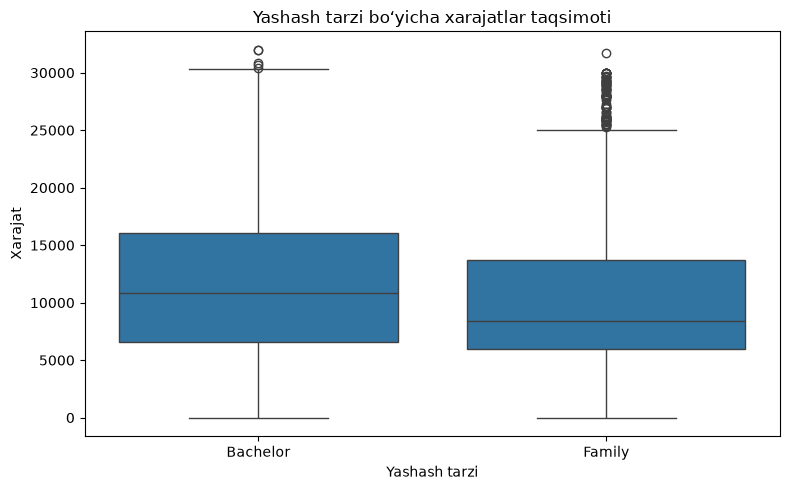

In [61]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Living_style', y='Cost_without_study')
plt.xlabel('Yashash tarzi')
plt.ylabel('Xarajat')
plt.title('Yashash tarzi bo‘yicha xarajatlar taqsimoti')
plt.tight_layout()
plt.show()

**Natija izohi:**

*Shu yerga qisqa izoh yozing.*

## 34. Scatter plot

### NAMUNA — kichik datasetda yechim

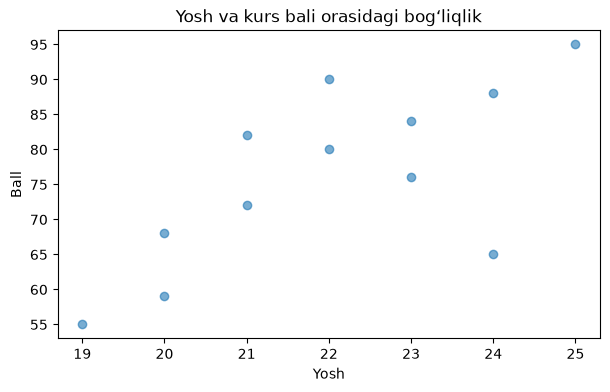

In [62]:
plt.figure(figsize=(7, 4))
plt.scatter(sample_df['Age_years'], sample_df['Score'], alpha=0.6)
plt.xlabel('Yosh')
plt.ylabel('Ball')
plt.title('Yosh va kurs bali orasidagi bog‘liqlik')
plt.show()

**Namuna izohi:** Nuqtalar umumiy yo‘nalish va tarqalishni ko‘rsatadi; `alpha` ustma-ust tushgan nuqtalarni ko‘rishni osonlashtiradi.

### MUSTAQIL TOPSHIRIQ 34 — Student_Depression_Dataset.csv

Age va CGPA orasidagi bog‘liqlikni scatter plot orqali ko‘rsating; nuqtalar ustma-ust tushishini kamaytirish uchun alpha parametridan foydalaning.

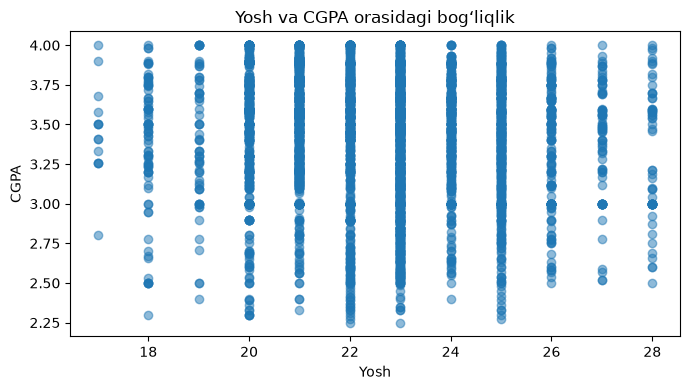

In [63]:
plt.figure(figsize=(7, 4))
plt.scatter(df['Age'], df['CGPA'], alpha=0.5)
plt.xlabel('Yosh')
plt.ylabel('CGPA')
plt.title('Yosh va CGPA orasidagi bog‘liqlik')
plt.tight_layout()
plt.show()

**Natija izohi:**

*Shu yerga qisqa izoh yozing.*

## 35. Heatmap

### NAMUNA — kichik datasetda yechim

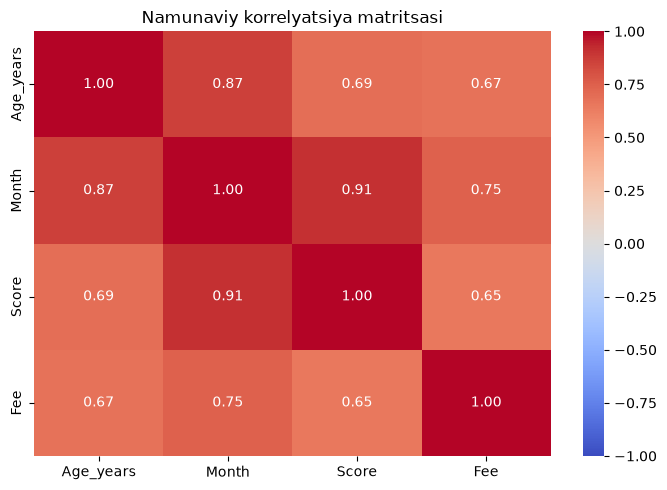

In [64]:
plt.figure(figsize=(7, 5))
sns.heatmap(sample_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Namunaviy korrelyatsiya matritsasi')
plt.tight_layout()
plt.show()

**Namuna izohi:** Rang va yozuvlar korrelyatsiya yo‘nalishi hamda kuchini ko‘rsatadi.

### MUSTAQIL TOPSHIRIQ 35 — Student_Depression_Dataset.csv

7-bosqichdagi korrelyatsiya matritsasini Seaborn heatmap orqali tasvirlang. Qiymatlarni grafik ichida ko‘rsating.

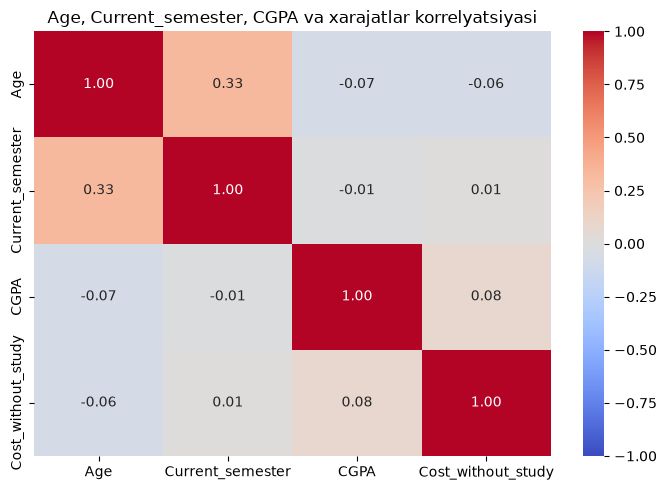

In [65]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Age, Current_semester, CGPA va xarajatlar korrelyatsiyasi')
plt.tight_layout()
plt.show()

**Natija izohi:**

*Shu yerga qisqa izoh yozing.*

## 36. Guruhlar bo‘yicha foizli bar chart

### NAMUNA — kichik datasetda yechim

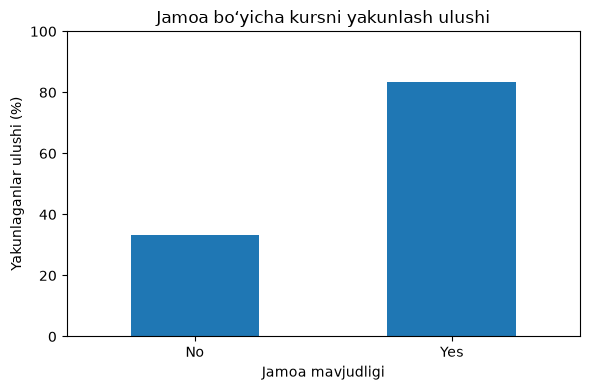

,count,Percent
Team,,
No,6,33.33
Yes,6,83.33


In [66]:
sample_team_summary['Percent'].plot(kind='bar', figsize=(6, 4), rot=0)
plt.xlabel('Jamoa mavjudligi')
plt.ylabel('Yakunlaganlar ulushi (%)')
plt.ylim(0, 100)
plt.title('Jamoa bo‘yicha kursni yakunlash ulushi')
plt.tight_layout()
plt.show()
display(sample_team_summary[['count', 'Percent']].round(2))

**Namuna izohi:** Foizlar guruh ichida hisoblanadi. Guruhlar soni bir xil bo‘lmasa, foizlarni guruh hajmi bilan birga talqin qilish kerak.

### MUSTAQIL TOPSHIRIQ 36 — Student_Depression_Dataset.csv

friend_circle bo‘yicha Depression = Yes ulushini foizlarda bar chart orqali ko‘rsating. 27-topshiriq natijasidan foydalaning. Guruhlar soni turlicha ekanini hisobga oling.

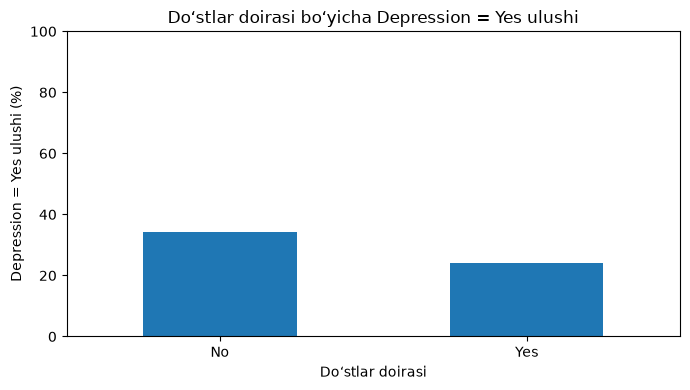

,Yes_percent,Student_count
friend_circle,,
No,34.267414,1249
Yes,24.043546,3215


In [67]:
friend_summary['Yes_percent'].plot(kind='bar', figsize=(7, 4), rot=0)
plt.xlabel('Do‘stlar doirasi')
plt.ylabel('Depression = Yes ulushi (%)')
plt.ylim(0, 100)
plt.title('Do‘stlar doirasi bo‘yicha Depression = Yes ulushi')
plt.tight_layout()
plt.show()
display(friend_summary[['Yes_percent', 'Student_count']])

**Natija izohi:**

*Shu yerga qisqa izoh yozing.*

---
# Yakuniy hisobot va topshirish
1-bosqichdagi uchta savolga hisob-kitoblar va grafiklar asosida javob bering. 5–7 gapdan iborat xulosa yozing: eng muhim topilmalar, bitta kutilmagan natija va kamida bitta cheklov. Sabab-oqibat yoki individual tashxis haqida da’vo qilmang.

**Javobingiz:**

Tahlilda talabalar yoshi, akademik natijalari, semestri, yashash tarzi, xarajatlari va Depression belgisi o‘rganildi. Living_style guruhlari bo‘yicha o‘rtacha hamda median xarajatlar solishtirildi, CGPA va boshqa sonli ko‘rsatkichlar uchun tavsifiy statistika va korrelyatsiya hisoblandi. Depression = Yes ulushi umumiy hamda Living_style va friend_circle guruhlari kesimida ko‘rib chiqildi. Grafiklar taqsimotlar va guruhlar orasidagi farqlarni ko‘rgazmali taqdim etishga yordam berdi. Kutilmagan natija sifatida [tahlilda kuzatilgan aniq natijani yozing]. Tahlilning cheklovi shundaki, natijalar faqat ushbu datasetdagi ma’lumotlarga asoslanadi va korrelyatsiya sabab-oqibatni isbotlamaydi. Depression ustuni klinik tashxis sifatida talqin qilinmaydi.

### Topshiriladigan fayllar
- Ushbu `.ipynb` daftar (barcha natijalar va grafiklar bilan)
- `student_profile.csv`
- `student_profile.json`
- `students_clean.csv`

### Baholash (100 ball)
| Bosqich | Ball |
|---|---:|
| 1–3 | 25 |
| 4–5 | 20 |
| 6–7 | 25 |
| 8–9 | 20 |
| Yakuniy xulosa va tartibli daftar | 10 |
| Jami | 100 |